# Longitudinal Aberration

Longitudinal aberration shows where each zone of the pupil brings an on-axis ray to focus, measured along the axis from the image surface. Plotting it for several wavelengths shows spherical aberration and spherochromatism (the change of spherical aberration with wavelength) at a glance.

In [1]:
from optiland.analysis import LongitudinalAberration
from optiland.samples.objectives import DoubleGauss

In [2]:
lens = DoubleGauss()

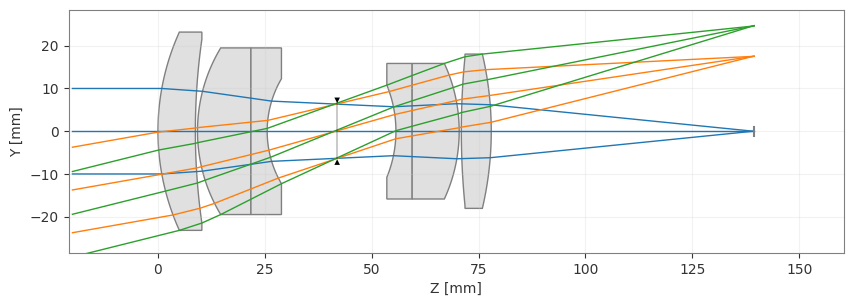

In [3]:
fig, ax = lens.draw()

For each wavelength, one on-axis ray is traced through each pupil zone `Py` from near 0 to 1. In the image surface's local frame, its axis crossing measured from the image surface vertex is `Δz = z − y · N / M`, where `(y, z)` is where the ray lands on the image surface and `M, N` are its direction cosines. On a flat image surface `z = 0`.

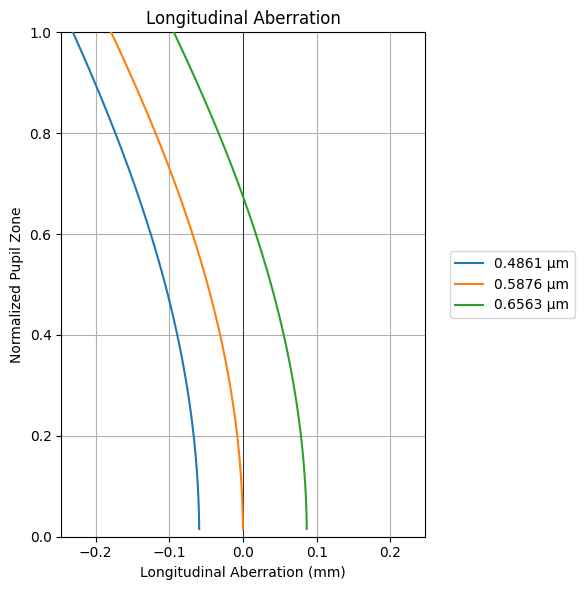

In [4]:
la = LongitudinalAberration(lens)
fig, ax = la.view()

How to read the plot:

- The y-axis is the normalized pupil zone, from the axis (0) to the edge of the pupil (1). The x-axis is the focus position of that zone, in mm from the image surface. For this lens the light travels toward +z, so a positive value means the zone focuses past the image surface.
- A vertical line means no spherical aberration: every zone focuses at the same place. Curvature of a line is spherical aberration.
- The horizontal gap between wavelengths at the smallest zone (the bottom of each curve) is axial color. A change in the shape of the curves between wavelengths is spherochromatism.

Near the axis, the curves meet the paraxial focus. The paraxial focus offset from the image surface is `−y/u` of a paraxial marginal ray:

In [5]:
import optiland.backend as be

la_fine = LongitudinalAberration(lens, num_points=256)
for wp, dz in zip(la_fine.wavelengths, la_fine.data["delta_z"]):
    lens.paraxial.trace(0, 1, wp.value)
    paraxial = -lens.surfaces.y[-1] / lens.surfaces.u[-1]
    print(
        f"{wp.value:.4f} µm: smallest zone {float(dz[0]):+.5f} mm, "
        f"paraxial focus {float(be.to_numpy(paraxial).ravel()[0]):+.5f} mm"
    )

0.4861 µm: smallest zone -0.05938 mm, paraxial focus -0.05938 mm
0.5876 µm: smallest zone +0.00001 mm, paraxial focus +0.00001 mm
0.6563 µm: smallest zone +0.08655 mm, paraxial focus +0.08655 mm
